***PIPELINE***

# PayGuard - Part A: Fraud Detection Prototype

In [92]:
!pip install -q lightgbm

In [93]:
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from lightgbm import LGBMClassifier
from scipy.stats import ks_2samp
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix,
                             precision_recall_curve, precision_score,
                             recall_score, roc_auc_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

SEED = 42
TRAIN_FRAC, VAL_FRAC = 0.70, 0.15
DATA_PATH = next((p for p in ["data/creditcard.csv", "creditcard.csv", "/content/creditcard.csv"] if os.path.exists(p)), "data/creditcard.csv")  # download: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud
FP_COST = 10.0  # illustrative assumption; replace with PayGuard business cost in production

## 1. Look at the data first

In [94]:
df_raw = pd.read_csv(DATA_PATH)
print("shape:", df_raw.shape)
df_raw.head()

shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [95]:
print("missing values:", df_raw.isnull().sum().sum())
print("duplicate rows:", df_raw.duplicated().sum())
df_raw.info()

missing values: 0
duplicate rows: 1081
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     2

In [96]:
counts = df_raw["Class"].value_counts()
print(counts)
print(f"\nfraud rate: {df_raw['Class'].mean() * 100:.4f}%")
print("A model that always says 'legitimate' would score "
      f"{(1 - df_raw['Class'].mean()) * 100:.2f}% accuracy, so accuracy tells us nothing.")

Class
0    284315
1       492
Name: count, dtype: int64

fraud rate: 0.1727%
A model that always says 'legitimate' would score 99.83% accuracy, so accuracy tells us nothing.


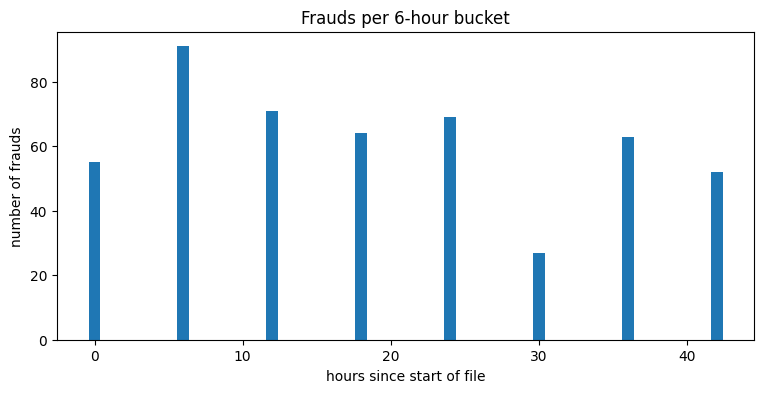

,frauds,fraud_rate_%
Time,,
0,55,0.446
1,91,0.260
2,71,0.152
3,64,0.127
4,69,0.595
5,27,0.075
6,63,0.127
7,52,0.121


In [97]:
# Does fraud look the same all the way through the 2 days? (6-hour buckets)
bucket = (df_raw["Time"] // (6 * 3600)).astype(int)
by_bucket = df_raw.groupby(bucket)["Class"].agg(["sum", "mean"])
by_bucket["mean"] *= 100

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(by_bucket.index * 6, by_bucket["sum"])
ax.set_xlabel("hours since start of file")
ax.set_ylabel("number of frauds")
ax.set_title("Frauds per 6-hour bucket")
plt.show()
by_bucket.rename(columns={"sum": "frauds", "mean": "fraud_rate_%"}).round(3)

## 2. Preprocessing

| Step                        | What I did                                                                                                          | Why I did it                                                                                                                                                                     |
| --------------------------- | ------------------------------------------------------------------------------------------------------------------- | -------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| Data checks                 | Checked that all required columns were present, `Class` contained only 0 and 1, and there were no negative amounts. | To catch invalid data before training the models.                                                                                                                                |
| Missing and infinite values | Removed rows with missing or infinite values. There were none in the dataset.                                       | No imputation was needed.                                                                                                                                                        |
| Duplicates                  | Removed exact duplicate rows.                                                                                       | To avoid duplicate transactions affecting the evaluation results.                                                                                                                |
| Sorting                     | Sorted transactions by `Time`, from oldest to newest.                                                               | To keep the training, validation, and test split in chronological order.                                                                                                         |
| Outliers                    | Kept extreme values.                                                                                                | Unusual transaction amounts or feature values could help identify fraud.                                                                                                         |
| `Time`                      | Removed it from the model features.                                                                                 | It represents seconds since the dataset started and may not provide a reliable time pattern. In production, useful time-based and transaction-frequency features could be added. |
| `Amount`                    | Applied `log1p` to transaction amounts and kept the original amounts for cost calculations.                         | Transaction amounts are highly skewed, so the transformation helps reduce the effect of large values.                                                                            |
| Scaling                     | Used `StandardScaler` for Logistic Regression, fitted on training data only through a `Pipeline`.                   | Logistic Regression benefits from scaling, while LightGBM does not require it. The `V1`–`V28` features are already PCA-transformed.                                              |
| Class imbalance             | Used class weights instead of SMOTE.                                                                                | This helps the models handle the imbalance without creating synthetic transactions.                                                                                              |


In [98]:
# integrity checks
expected = {"Time", "Amount", "Class"} | {f"V{i}" for i in range(1, 29)}
assert expected.issubset(df_raw.columns), f"missing columns: {expected - set(df_raw.columns)}"
assert set(df_raw["Class"].unique()) <= {0, 1}, "Class must be 0/1"
assert (df_raw["Amount"] >= 0).all(), "negative amounts found"

n_inf = int(np.isinf(df_raw.select_dtypes("number")).sum().sum())
print("infinite values:", n_inf)

infinite values: 0


In [99]:
# cleaning
df = (df_raw.replace([np.inf, -np.inf], np.nan)
            .dropna()
            .drop_duplicates()
            .astype({"Class": int})
            .sort_values("Time")
            .reset_index(drop=True))

print(f"rows: {len(df_raw)} -> {len(df)}  (removed {len(df_raw) - len(df)})")
print(f"fraud rate after cleaning: {df['Class'].mean() * 100:.4f}%")

rows: 284807 -> 283726  (removed 1081)
fraud rate after cleaning: 0.1667%


In [100]:
# features
amount_raw = df["Amount"].to_numpy()       # real money, only used for the cost calculation
y = df["Class"].to_numpy()

X = df.drop(columns=["Class", "Time"])
X["Amount"] = np.log1p(X["Amount"])

constant_cols = [c for c in X.columns if X[c].nunique() == 1]
if constant_cols:
    print("dropping constant columns:", constant_cols)
    X = X.drop(columns=constant_cols)

print("features used:", X.shape[1])

features used: 29


## 3. Chronological Split

I split the data by time instead of using a random split. This better reflects how the model would work in real life, where it learns from past transactions and predicts future ones. It also helps reveal changes in fraud patterns over time.

* **Training set (70%):** The oldest transactions, used to train the models.
* **Validation set (15%):** The next set of transactions, used to compare models and choose the best decision threshold.
* **Test set (15%):** The newest transactions, kept separate for the final evaluation.

I used the validation set to make model-selection decisions and kept the test set for reporting the final results.


In [101]:
n = len(df)
a, b = int(n * TRAIN_FRAC), int(n * (TRAIN_FRAC + VAL_FRAC))

X_tr, y_tr = X.iloc[:a], y[:a]
X_va, y_va, amt_va = X.iloc[a:b], y[a:b], amount_raw[a:b]
X_te, y_te, amt_te = X.iloc[b:], y[b:], amount_raw[b:]

for name, yy in [("train", y_tr), ("val", y_va), ("test", y_te)]:
    print(f"{name:<5}: {len(yy):>7} rows, {int(yy.sum()):>3} frauds")

train:  198608 rows, 366 frauds
val  :   42559 rows,  55 frauds
test :   42559 rows,  52 frauds


In [102]:
# Drift check: how different is the newest data from the oldest?
# KS statistic: 0 = identical, 1 = completely different.
shift = pd.Series({c: ks_2samp(X_tr[c], X_te[c]).statistic for c in X.columns})
print("largest train-vs-test shifts (KS statistic):")
print(shift.sort_values(ascending=False).head(5).round(3))

largest train-vs-test shifts (KS statistic):
V3     0.398
V1     0.302
V28    0.252
V25    0.249
V15    0.192
dtype: float64


## 4. Models

I used two models to compare their performance on fraud detection.

* **Logistic Regression (Baseline):** A simple and fast model that is easy to understand. I used scaled features to help it perform well.
* **LightGBM:** A gradient-boosting model that can capture more complex patterns in transaction data and make predictions quickly.

I kept the model settings fixed and did not use extensive hyperparameter tuning or ensembling. The goal was to make a fair, straightforward comparison between the two models rather than focus on achieving the highest possible score.

I did not try a neural network because I wanted to keep the project simple and focused on comparing these two approaches.


In [103]:
models = {
    "Logistic Regression (baseline)": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(class_weight="balanced", max_iter=1000,
                                   random_state=SEED)),
    ]),
    "LightGBM": LGBMClassifier(
        n_estimators=300, learning_rate=0.05, num_leaves=31,
        subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
        class_weight="balanced", random_state=SEED, n_jobs=-1, verbosity=-1),
}

for name, model in models.items():
    model.fit(X_tr, y_tr)
    print("trained:", name)

trained: Logistic Regression (baseline)
trained: LightGBM


## 5. Evaluation Metrics

I focused on metrics that better measure fraud detection, since fraudulent transactions are rare.

* **PR-AUC:** Main metric for comparing how well the models detect fraud.
* **ROC-AUC:** Reported as an additional performance measure.
* **Precision and Recall:** Show how many alerts are genuine fraud and how many fraud cases are caught.
* **Expected Cost:** Estimates losses from missed fraud and the cost of false alarms.

**Cost Assumption:** I used an illustrative cost of `$10` per false alarm because actual cost was not provided. Missed fraud is estimated using the transaction amount. These assumptions should be replaced with real business costs before production use.


In [104]:
def cost(y_true, pred, amounts, fp_cost=FP_COST):
    missed = (y_true == 1) & (pred == 0)         # fraud we let through
    false_alarm = (y_true == 0) & (pred == 1)    # good customer we bothered
    return amounts[missed].sum() + fp_cost * false_alarm.sum()


def best_threshold(y_true, proba, amounts, fp_cost=FP_COST):
    """Lowest-cost threshold. Only ever call this on the validation set."""
    candidates = np.unique(np.concatenate([np.linspace(0.01, 0.99, 99),
                                           proba[y_true == 1]]))
    costs = np.array([cost(y_true, (proba >= t).astype(int), amounts, fp_cost)
                      for t in candidates])
    return float(candidates[np.flatnonzero(costs == costs.min())[-1]])   # ties -> higher threshold


def report(name, y_true, proba, amounts, t):
    pred = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {"Model": name, "Threshold": round(t, 4),
            "PR-AUC": average_precision_score(y_true, proba),
            "ROC-AUC": roc_auc_score(y_true, proba),
            "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred, zero_division=0),
            "TP": tp, "FP": fp, "FN": fn, "Cost": cost(y_true, pred, amounts)}

## 6. Results

I selected the model based on validation PR-AUC and chose the decision threshold using the validation set and the estimated business cost. I kept the test set only for the final evaluation to avoid using it to make decisions.

### Operating Threshold

The selected LightGBM threshold is **0.022** on the validation set. This is a model-score threshold, not a calibrated 2.2% probability of fraud, because class weighting affects the model's scores. Before production use, the threshold should be reviewed using PayGuard's actual costs of missed fraud and false alarms.


In [105]:
p_va = {name: m.predict_proba(X_va)[:, 1] for name, m in models.items()}
p_te = {name: m.predict_proba(X_te)[:, 1] for name, m in models.items()}
thr = {name: best_threshold(y_va, p_va[name], amt_va) for name in models}

val_tbl = pd.DataFrame([report(n_, y_va, p_va[n_], amt_va, thr[n_]) for n_ in models])
test_tbl = pd.DataFrame([report(n_, y_te, p_te[n_], amt_te, thr[n_]) for n_ in models])

print("VALIDATION (used to choose model and threshold)")
display(val_tbl)
print("TEST (reporting only)")
display(test_tbl)

best = val_tbl.sort_values("PR-AUC", ascending=False).iloc[0]["Model"]
print(f"\nselected on validation: {best}  |  threshold {thr[best]:.4f}")

# reference points for the cost discussion
test_cost = test_tbl.set_index("Model").loc[best, "Cost"]
cost_nothing = amt_te[y_te == 1].sum()
print(f"cost if we block nothing   : {cost_nothing:,.0f}")
print(f"cost if we flag everything : {FP_COST * (y_te == 0).sum():,.0f}")
print(f"cost with {best:<17}: {test_cost:,.0f}  ({(1 - test_cost / cost_nothing) * 100:.0f}% lower than blocking nothing)")

VALIDATION (used to choose model and threshold)


,Model,Threshold,PR-AUC,ROC-AUC,Precision,Recall,TP,FP,FN,Cost
0,Logistic Regression (baseline),0.9991,0.812298,0.980728,0.578947,0.800000,44,32,11,486.53
1,LightGBM,0.0220,0.863877,0.983954,0.640000,0.872727,48,27,7,431.55


TEST (reporting only)


,Model,Threshold,PR-AUC,ROC-AUC,Precision,Recall,TP,FP,FN,Cost
0,Logistic Regression (baseline),0.9991,0.690712,0.976533,0.639344,0.75,39,22,13,2592.4
1,LightGBM,0.0220,0.763061,0.971844,0.609375,0.75,39,25,13,2622.4



selected on validation: LightGBM  |  threshold 0.0220
cost if we block nothing   : 6,169
cost if we flag everything : 425,070
cost with LightGBM         : 2,622  (57% lower than blocking nothing)


### Threshold Sensitivity

The threshold affects how much fraud the model catches and how many false alerts it generates. A lower threshold usually catches more fraud but also flags more legitimate transactions, while a higher threshold reduces false alerts but may miss more fraud.

I tested different thresholds on the validation set to understand this trade-off. Since the validation set contains only 55 fraud cases, the estimated cost can change significantly if even one high-value fraud is missed. Therefore, I treat `0.022` as a starting point rather than a perfect threshold.


In [106]:
# Sensitivity of the selected LightGBM threshold on validation data
sensitivity_thresholds = sorted({0.01, thr[best], 0.05, 0.10, 0.20, 0.50})
sensitivity_rows = []

for t in sensitivity_thresholds:
    pred_t = (p_va[best] >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_va, pred_t).ravel()
    precision = precision_score(y_va, pred_t, zero_division=0)
    recall = recall_score(y_va, pred_t, zero_division=0)
    total_cost = cost(y_va, pred_t, amt_va)

    sensitivity_rows.append({
        "Threshold": t,
        "Precision": round(precision, 3),
        "Recall": round(recall, 3),
        "FP": fp,
        "FN": fn,
        "Cost": round(total_cost, 2),
    })

sensitivity_tbl = pd.DataFrame(sensitivity_rows)
display(sensitivity_tbl)

,Threshold,Precision,Recall,FP,FN,Cost
0,0.010000,0.552,0.873,39,7,551.55
1,0.021999,0.640,0.873,27,7,431.55
2,0.050000,0.807,0.836,11,9,511.03
3,0.100000,0.846,0.800,8,11,482.79
4,0.200000,0.875,0.764,6,13,1459.83
5,0.500000,0.913,0.764,4,13,1439.83


### False Positives vs. False Negatives

* **False negative (missed fraud):** The model fails to detect a fraudulent transaction. I estimate this cost using the transaction amount, although real losses may also include chargeback fees and loss of customer trust.
* **False positive (false alarm):** The model flags a legitimate transaction. I used an assumed cost of `$10` per false alarm to represent review effort and customer inconvenience.
* **Impact on the threshold:** Since missed fraud can be much more expensive than a false alarm, the selected threshold is relatively low at `0.022`. However, the right threshold depends on PayGuard's actual costs.

In production, a tiered approach could work better: block high-risk transactions, send medium-risk transactions for additional verification or review, and approve low-risk transactions.


### Real-Time Inference

In production, transactions must be scored quickly using only information available at authorization time. Features such as recent transaction activity, spending patterns, and device changes could improve fraud detection. LightGBM provides fast predictions, while fallback rules or manual review can help when the model is unavailable.


### Conclusion

LightGBM performed better than Logistic Regression on PR-AUC for both validation (0.864 vs. 0.812) and test data (0.763 vs. 0.691), so I selected it as the preferred model.

However, test performance dropped, and the estimated costs were very similar ($2,622 for LightGBM vs. $2,592 for Logistic Regression). The test set also showed signs of data drift, meaning transaction patterns may change over time.

Overall, the results are promising, but production use would require realistic business costs, threshold adjustments, drift monitoring, real-time features, and regular model retraining.


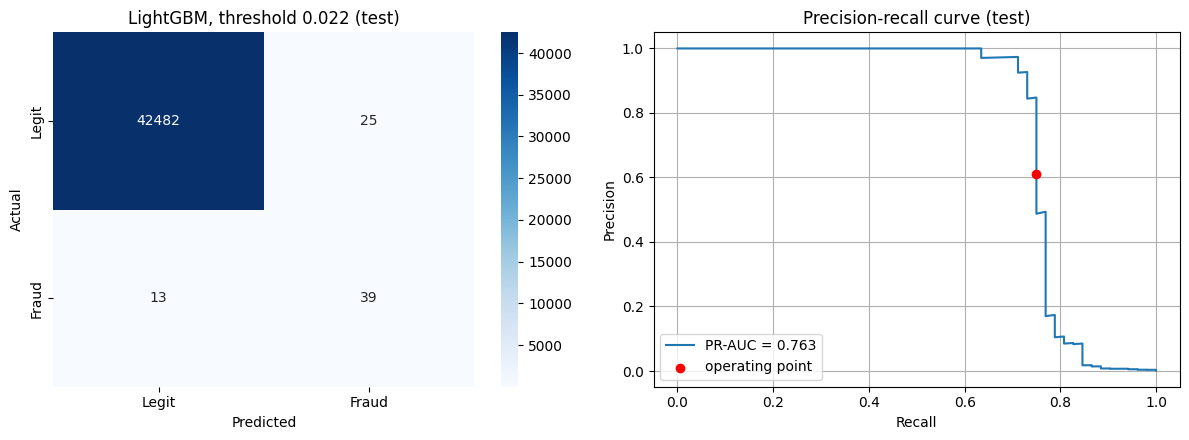

In [107]:
pred = (p_te[best] >= thr[best]).astype(int)
row = test_tbl.set_index("Model").loc[best]
prec, rec, _ = precision_recall_curve(y_te, p_te[best])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.heatmap(confusion_matrix(y_te, pred), annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["Legit", "Fraud"], yticklabels=["Legit", "Fraud"])
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")
axes[0].set_title(f"{best}, threshold {thr[best]:.3f} (test)")

axes[1].plot(rec, prec, label=f"PR-AUC = {row['PR-AUC']:.3f}")
axes[1].scatter([row["Recall"]], [row["Precision"]], color="red", zorder=3,
                label="operating point")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-recall curve (test)")
axes[1].legend()
axes[1].grid(True)
plt.tight_layout()
plt.show()

In [108]:
def predict_new_transaction(transaction_data, model, threshold):
    """
    Score ONE new transaction.
    Input: dict with RAW V1..V28 and RAW Amount (real money, not log-transformed).
    The same log1p transform used in training is applied here, exactly once.
    """
    row = pd.DataFrame([transaction_data])

    missing = set(X.columns) - set(row.columns)
    assert not missing, f"missing features: {missing}"

    row["Amount"] = np.log1p(row["Amount"])        # same preprocessing as training
    row = row[X.columns]                           # exact feature order the model saw

    fraud_score = float(model.predict_proba(row)[0, 1])
    prediction = int(fraud_score >= threshold)

    return {"fraud_score": round(fraud_score, 6),
            "prediction": prediction,
            "result": "FRAUD" if prediction == 1 else "LEGITIMATE"}

In [109]:
# Synthetic example: all-zero PCA features, raw amount of 100
new_transaction = {f"V{i}": 0.0 for i in range(1, 29)}
new_transaction["Amount"] = 100.0

In [110]:
result = predict_new_transaction(new_transaction, model=models[best], threshold=thr[best])
print(result)

{'fraud_score': 7.2e-05, 'prediction': 0, 'result': 'LEGITIMATE'}


In [111]:
# Demo on real rows from the TEST period (never used for fitting or threshold choice).
# Rows come from `df` so Amount is RAW, which is what predict_new_transaction expects.
raw_features = df.drop(columns=["Class", "Time"])

fraud_pos = b + int(np.where(y_te == 1)[0][0])    # first fraud in the test period
legit_pos = b + int(np.where(y_te == 0)[0][0])    # first legit row in the test period

for label, pos in [("fraud", fraud_pos), ("legit", legit_pos)]:
    res = predict_new_transaction(raw_features.iloc[pos].to_dict(),
                                  model=models[best], threshold=thr[best])
    print(f"actual={label:<5} ->", res)

actual=fraud -> {'fraud_score': 0.999984, 'prediction': 1, 'result': 'FRAUD'}
actual=legit -> {'fraud_score': 2e-06, 'prediction': 0, 'result': 'LEGITIMATE'}
